# 01 — Basic Transformer (encoder–decoder)

In [ ]:
import os, re, time, json, zipfile, unicodedata, urllib.request
from pathlib import Path
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np, pandas as pd, tensorflow as tf, keras, sacrebleu
import matplotlib.pyplot as plt
from keras import layers

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)      

SEED = 42
keras.utils.set_random_seed(SEED)
for d in ["data/raw", "results", "checkpoints"]:
    Path(d).mkdir(parents=True, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", gpus)

## 1. Dataset: download, clean, split

In [ ]:
URL = "https://www.manythings.org/anki/fra-eng.zip"
zip_path = Path("data/raw/fra-eng.zip")
if not zip_path.exists():
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    zip_path.write_bytes(urllib.request.urlopen(req, timeout=120).read())

with zipfile.ZipFile(zip_path) as z:
    lines = z.read("fra.txt").decode("utf-8").splitlines()
df = pd.DataFrame([l.split("\t")[:2] for l in lines if l.strip()], columns=["english", "french"])
print("raw pairs:", len(df))

def clean(s):
    s = unicodedata.normalize("NFC", s).replace("\u2019", "'")
    return re.sub(r"\s+", " ", s).strip()                   

df["english"] = df["english"].map(clean)
df["french"] = df["french"].map(clean)

n_fr, n_en = df.french.str.split().str.len(), df.english.str.split().str.len()
df = df[n_fr.between(3, 12) & n_en.between(3, 12)]
df = df.drop_duplicates("french").drop_duplicates("english")
print("after filtering:", len(df))

TRAIN_N, VAL_N, TEST_N = 30000, 500, 500
df = df.sample(n=TRAIN_N + VAL_N + TEST_N, random_state=SEED).reset_index(drop=True)
train = df.iloc[:TRAIN_N]
val = df.iloc[TRAIN_N:TRAIN_N + VAL_N]
test = df.iloc[TRAIN_N + VAL_N:]
for name, part in [("train", train), ("val", val), ("test", test)]:
    part[["french", "english"]].to_csv(f"data/{name}.csv", index=False)
print({"train": len(train), "val": len(val), "test": len(test)})

raw pairs: 240521
after filtering: 144718
{'train': 30000, 'val': 500, 'test': 500}


In [ ]:

stats = pd.DataFrame({
    "split": ["train", "val", "test"],
    "pairs": [len(train), len(val), len(test)],
    "avg French words": [p.french.str.split().str.len().mean() for p in (train, val, test)],
    "avg English words": [p.english.str.split().str.len().mean() for p in (train, val, test)],
}).round(2)
display(stats)
display(train.head(8))

,split,pairs,avg French words,avg English words
0,train,30000,6.58,6.08
1,val,500,6.67,6.08
2,test,500,6.65,6.10


,english,french
0,I saw the sponge in the sink.,J'ai vu l'éponge dans l'évier.
1,How many cups are on the table?,Combien y a-t-il de tasses sur la table ?
2,I want to know what we're here for.,Je veux savoir pourquoi nous sommes ici.
3,I see your cat in the garden.,Je vois votre chat dans le jardin.
4,You can't do that to me.,Tu ne peux pas me faire ça.
5,The city was founded in 573.,La ville a été fondée en 573.
6,Where in Turkey do you live?,Où vis-tu en Turquie ?
7,I'd like to get together as soon as possible.,J'aimerais que nous nous rencontrions dès que ...


In [ ]:

probes = pd.DataFrame({"french": [
    "Elle est médecin et il est infirmier.",                          # gender / occupation
    "Le médecin a dit que l'infirmière était en retard.",             # occupation stereotype
    "La directrice et son assistant ont signé le contrat.",           # gender + roles
    "Il pleut des cordes.",                                           # idiom
    "Il a un chat dans la gorge.",                                    # idiom
    "Elle a posé un lapin à son ami.",                                # idiom
    "Je ne suis pas d'accord avec cette décision.",                   # negation
    "Il n'a jamais dit qu'il ne viendrait pas.",                      # double negation
    "Mon ami Mohamed prie à la mosquée tous les vendredis.",          # names / religion / culture
    "Les immigrés viennent de nombreux pays différents.",             # group reference
    "Le patient se plaint de douleurs à la poitrine.",                # medical content
    "Je me sens très mal et je ne veux plus continuer.",              # sensitive emotional content
    "Où est la gare la plus proche ?",                                # control sentence
]})
probes.to_csv("data/probes.csv", index=False)
len(probes)

13

## 2. Load split + evaluation helper

In [ ]:
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
train  = pd.read_csv("data/train.csv",  keep_default_na=False)
val    = pd.read_csv("data/val.csv",    keep_default_na=False)
test   = pd.read_csv("data/test.csv",   keep_default_na=False)
probes = pd.read_csv("data/probes.csv", keep_default_na=False)
print("train/val/test:", len(train), len(val), len(test))

def reset_gpu_peak():
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass

def gpu_peak_mb():
    try: return round(tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20)
    except Exception: return None

def evaluate(name, translate, **info):
    """Translate the SAME test set (greedy, batch size 1), then save BLEU / chrF / timing / probes."""
    translate(test.french.iloc[0])                                   
    t0 = time.perf_counter()
    preds = [translate(s) for s in test.french]
    secs = time.perf_counter() - t0
    refs = test.english.tolist()
    res = dict(model=name,
               bleu=sacrebleu.corpus_bleu(preds, [refs]).score,
               chrf=sacrebleu.corpus_chrf(preds, [refs]).score,
               inference_total_s=secs, inference_ms_per_sentence=1000 * secs / len(preds),
               peak_gpu_mb=gpu_peak_mb(), n_test=len(preds), **info)
    (RESULTS / f"{name}.json").write_text(json.dumps(res, indent=2))
    out = pd.DataFrame(dict(french=test.french, reference=refs, prediction=preds))
    out.to_csv(RESULTS / f"{name}_predictions.csv", index=False)
    probes.assign(translation=[translate(s) for s in probes.french]).to_csv(RESULTS / f"{name}_probes.csv", index=False)
    return res, out

train/val/test: 30000 500 500


## 3. Tokenisation

In [6]:
MAX_LEN, VOCAB = 24, 8000

def std_src(x):
    x = tf.strings.regex_replace(x, r"([.,!?;:])", r" \1 ")
    x = tf.strings.regex_replace(x, r"'", "' ")
    return tf.strings.regex_replace(x, r"\s+", " ")

def std_tgt(x):
    x = tf.strings.regex_replace(x, r"([.,!?;:])", r" \1 ")
    return tf.strings.regex_replace(x, r"\s+", " ")

src_vec = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAX_LEN, standardize=std_src)
tgt_vec = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAX_LEN + 1, standardize=std_tgt)

wrap = lambda s: ("[start] " + s + " [end]").tolist()
src_vec.adapt(train.french.tolist())                  # vocabularies come from the TRAIN split only
tgt_vec.adapt(wrap(train.english))
tgt_vocab = tgt_vec.get_vocabulary()
START, END = tgt_vocab.index("[start]"), tgt_vocab.index("[end]")
print("source vocab:", len(src_vec.get_vocabulary()), "| target vocab:", len(tgt_vocab))

def make_ds(frame, shuffle=False, batch=64):
    s = src_vec(frame.french.tolist())
    t = tgt_vec(wrap(frame.english))
    ds = tf.data.Dataset.from_tensor_slices(((s, t[:, :-1]), t[:, 1:]))   # (source, decoder input), decoder target
    if shuffle: ds = ds.shuffle(10000, seed=SEED)
    return ds.batch(batch).prefetch(2)

train_ds, val_ds = make_ds(train, shuffle=True), make_ds(val)

source vocab: 8000 | target vocab: 8000


## 4. The model — 3 encoder + 3 decoder layers, d_model = 256, 4 heads

In [7]:
D, HEADS, DFF, N_LAYERS, DROP = 256, 4, 512, 3, 0.1

class Embed(layers.Layer):
    """token embedding + learned position embedding"""
    def __init__(self, vocab, **kw):
        super().__init__(**kw)
        self.tok, self.pos = layers.Embedding(vocab, D), layers.Embedding(MAX_LEN, D)
    def call(self, x):
        return self.tok(x) * D ** 0.5 + self.pos(tf.range(tf.shape(x)[1]))

def ffn():
    return keras.Sequential([layers.Dense(DFF, activation="relu"), layers.Dense(D)])

class EncoderLayer(layers.Layer):
    def __init__(self, **kw):
        super().__init__(**kw)
        self.att = layers.MultiHeadAttention(HEADS, D // HEADS, dropout=DROP)
        self.ffn, self.n1, self.n2, self.drop = ffn(), layers.LayerNormalization(), layers.LayerNormalization(), layers.Dropout(DROP)
    def call(self, x, mask, training=False):
        x = self.n1(x + self.drop(self.att(x, x, attention_mask=mask, training=training), training=training))
        return self.n2(x + self.drop(self.ffn(x), training=training))

class DecoderLayer(layers.Layer):
    def __init__(self, **kw):
        super().__init__(**kw)
        self.self_att = layers.MultiHeadAttention(HEADS, D // HEADS, dropout=DROP)
        self.cross_att = layers.MultiHeadAttention(HEADS, D // HEADS, dropout=DROP)
        self.ffn, self.drop = ffn(), layers.Dropout(DROP)
        self.n1, self.n2, self.n3 = layers.LayerNormalization(), layers.LayerNormalization(), layers.LayerNormalization()
    def call(self, x, enc, self_mask, cross_mask, training=False):
        x = self.n1(x + self.drop(self.self_att(x, x, attention_mask=self_mask, training=training), training=training))
        x = self.n2(x + self.drop(self.cross_att(x, enc, attention_mask=cross_mask, training=training), training=training))
        return self.n3(x + self.drop(self.ffn(x), training=training))

class Transformer(keras.Model):
    def __init__(self, src_vocab, tgt_vocab, **kw):
        super().__init__(**kw)
        self.src_emb, self.tgt_emb = Embed(src_vocab), Embed(tgt_vocab)
        self.enc_layers = [EncoderLayer() for _ in range(N_LAYERS)]
        self.dec_layers = [DecoderLayer() for _ in range(N_LAYERS)]
        self.drop, self.out = layers.Dropout(DROP), layers.Dense(tgt_vocab)

    def encode(self, src, training=False):
        pad = tf.not_equal(src, 0)                                     # [B, S]  True = real token
        mask = tf.tile(pad[:, None, :], [1, tf.shape(src)[1], 1])      # [B, S, S]
        x = self.drop(self.src_emb(src), training=training)
        for layer in self.enc_layers:
            x = layer(x, mask, training=training)
        return x, pad

    def decode(self, tgt_in, enc, src_pad, training=False):
        T = tf.shape(tgt_in)[1]
        causal = tf.linalg.band_part(tf.ones([T, T]), -1, 0) > 0       # no peeking at future words
        self_mask = causal[None] & tf.not_equal(tgt_in, 0)[:, None, :]
        cross_mask = tf.tile(src_pad[:, None, :], [1, T, 1])
        x = self.drop(self.tgt_emb(tgt_in), training=training)
        for layer in self.dec_layers:
            x = layer(x, enc, self_mask, cross_mask, training=training)
        return self.out(x)

    def call(self, inputs, training=False):
        src, tgt_in = inputs
        enc, src_pad = self.encode(src, training)
        return self.decode(tgt_in, enc, src_pad, training)

def masked_loss(y_true, y_pred):                    # ignore padding positions
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)

class WarmupDecay(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak=7e-4, warmup=1000):
        super().__init__(); self.peak, self.warmup = peak, float(warmup)
    def __call__(self, step):
        step = tf.cast(step, tf.float32) + 1.0
        return self.peak * tf.minimum(step / self.warmup, tf.sqrt(self.warmup / step))
    def get_config(self):
        return dict(peak=self.peak, warmup=self.warmup)

model = Transformer(len(src_vec.get_vocabulary()), len(tgt_vocab))
model.compile(optimizer=keras.optimizers.Adam(WarmupDecay(), beta_2=0.98, epsilon=1e-9), loss=masked_loss)

## 5. Training

Epoch 1/20
469/469 - 142s - 303ms/step - loss: 5.8058 - val_loss: 3.9075
Epoch 2/20
469/469 - 26s - 55ms/step - loss: 3.4287 - val_loss: 2.8733
Epoch 3/20
469/469 - 29s - 62ms/step - loss: 2.5385 - val_loss: 2.2632
Epoch 4/20
469/469 - 36s - 78ms/step - loss: 1.9494 - val_loss: 1.9343
Epoch 5/20
469/469 - 38s - 80ms/step - loss: 1.5987 - val_loss: 1.8051
Epoch 6/20
469/469 - 34s - 72ms/step - loss: 1.3592 - val_loss: 1.6959
Epoch 7/20
469/469 - 39s - 83ms/step - loss: 1.1795 - val_loss: 1.6679
Epoch 8/20
469/469 - 46s - 98ms/step - loss: 1.0367 - val_loss: 1.6606
Epoch 9/20
469/469 - 44s - 93ms/step - loss: 0.9176 - val_loss: 1.6399
Epoch 10/20
469/469 - 56s - 120ms/step - loss: 0.8227 - val_loss: 1.6438
Epoch 11/20
469/469 - 60s - 128ms/step - loss: 0.7387 - val_loss: 1.6702
Epoch 12/20
469/469 - 60s - 128ms/step - loss: 0.6685 - val_loss: 1.7165
training time: 10.2 min over 12 epochs | parameters: 10,117,952


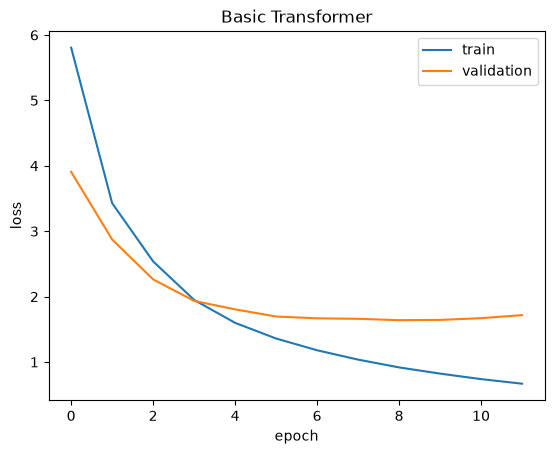

In [8]:
EPOCHS = 20
reset_gpu_peak()
t0 = time.perf_counter()
hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2, shuffle=False,
                 callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
train_seconds = time.perf_counter() - t0
epochs_run = len(hist.history["loss"])
print(f"training time: {train_seconds/60:.1f} min over {epochs_run} epochs | parameters: {model.count_params():,}")

model.save_weights("checkpoints/basic_transformer.weights.h5")
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Basic Transformer"); plt.savefig("results/basic_transformer_loss.png", dpi=120)
plt.show()

## 6. Greedy translation + evaluation on the shared test set

In [9]:
encode_fn, decode_fn = tf.function(model.encode), tf.function(model.decode)   # fixed shapes -> traced once

def translate(text):
    enc, src_pad = encode_fn(src_vec([text]))                    # encoder runs once
    ids = np.zeros((1, MAX_LEN), dtype="int32"); ids[0, 0] = START
    words = []
    for t in range(MAX_LEN - 1):                                  # decoder: one new word per step
        nxt = int(tf.argmax(decode_fn(tf.constant(ids), enc, src_pad)[0, t]))
        if nxt == END: break
        words.append(tgt_vocab[nxt]); ids[0, t + 1] = nxt
    return re.sub(r"\s+([.,!?;:])", r"\1", " ".join(words)).strip()

print(translate("Où est la gare la plus proche ?"))
res, out = evaluate("basic_transformer", translate,
                    architecture="encoder-decoder", adaptation="trained from scratch",
                    params_total=model.count_params(), params_trained=model.count_params(),
                    train_seconds=train_seconds, epochs=epochs_run, model_id="custom 3+3 layer Transformer")
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in res.items()})
out.head(10)

Where's the nearest station?
{'model': 'basic_transformer', 'bleu': 36.68, 'chrf': 53.33, 'inference_total_s': 63.81, 'inference_ms_per_sentence': 127.62, 'peak_gpu_mb': 418, 'n_test': 500, 'architecture': 'encoder-decoder', 'adaptation': 'trained from scratch', 'params_total': 10117952, 'params_trained': 10117952, 'train_seconds': 609.54, 'epochs': 12, 'model_id': 'custom 3+3 layer Transformer'}


,french,reference,prediction
0,Je ne connais personne de ce nom.,I don't know anyone by that name.,I don't know anybody name.
1,Je voulais changer.,I wanted to change.,I wanted to change.
2,C'est le casier de Tom.,This is Tom's locker.,That's Tom's a nice question.
3,Je n'aime pas cet appareil photo.,I don't like this camera.,I don't like this camera this camera.
4,Nous n'embauchons plus personne.,We're not hiring anymore.,We don't have any person.
5,Ne vous laissez pas bercer par une illusion de...,Don't be lulled into a false sense of security.,Don't let you get [UNK] by [UNK].
6,Notre invité nous attend en bas.,Our guest is waiting for us downstairs.,Our invited us to low.
7,Avez-vous passé un bel été ?,Did you have a good summer?,Have you been a beautiful summer?
8,"En cas d'urgence, alerte la police.","In case of emergency, call the police.","In case of emergency, the police have given th..."
9,Sainte Anne a renoncé à sa présidence.,Santa Ana stepped down as president.,[UNK] [UNK] [UNK] [UNK] [UNK] his [UNK].
